# Treinamento da DNN — Classificação de Comandos por Voz (Google Colab)

Este notebook:
1. Monta o Google Drive e extrai o CSV com os vetores de MFCC (gerado pelo script `extrair_mfcc_para_csv.py`), que está compactado em `.zip` dentro do Drive.
2. Reconstrói as matrizes de MFCC a partir do CSV e separa treino/validação/teste pelo número da gravação no nome do arquivo: as gravações 81 a 100 de cada comando vão somente para o teste; as gravações 1 a 80 são usadas para treino e validação.
3. Treina a mesma DNN do `codigo_tcc_corrigido_final.py`.
4. A cada vez que a validação melhora, salva o modelo automaticamente no Google Drive (assim o melhor modelo fica salvo mesmo que o Colab desconecte no meio do treino).
5. Usa early stopping: o treinamento para sozinho quando a rede converge (quando a validação para de melhorar por várias épocas seguidas), em vez de rodar um número fixo de épocas.
6. Avalia o melhor modelo salvo no conjunto de teste (acurácia, matriz de confusão, relatório de classificação, curva de loss).

## 1. Instalação e Imports

In [29]:
# Descomente se precisar instalar alguma biblioteca no ambiente do Colab
# !pip install torch torchaudio tabulate -q

import os
import glob
import re
import zipfile

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

from joblib import dump

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print('PyTorch:', torch.__version__)
print('GPU disponível:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU(s):', torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


PyTorch: 2.11.0+cu130
GPU disponível: True
GPU(s): Tesla T4


## 2. Montar o Google Drive e configurar caminhos / hiperparâmetros

In [30]:
from google.colab import drive
drive.mount('/content/drive')

# ---- AJUSTE AQUI ----

# Caminho do .zip, dentro do seu Drive, que contém o CSV gerado por
# extrair_mfcc_para_csv.py (ex.: 'mfcc_features.csv' dentro do zip)
DRIVE_ZIP_PATH = '/content/drive/MyDrive/dataset_tcc/mfcc_features.zip'

# Pasta no Drive onde o MELHOR modelo e o encoder serão salvos.
# Fica no Drive (não só no ambiente temporário do Colab) para não se
# perder se o Colab desconectar no meio do treino.
DRIVE_OUTPUT_DIR = '/content/drive/MyDrive/dataset_tcc/modelo'

# Pasta local (dentro do ambiente do Colab) onde o zip será extraído
EXTRACT_DIR = 'mfcc_csv'

# ---- Configurações de MFCC (devem bater com as usadas na extração) ----
"""N_MFCC = 60
MAX_TIME = 150"""
"""N_MFCC = 20
MAX_TIME = 100"""
N_MFCC = 20
MAX_TIME = 150

# ---- Hiperparâmetros de treino ----
BATCH_SIZE = 32
LEARNING_RATE = 0.0001
EPOCHS_MAX = 300          # teto de épocas; na prática o early stopping deve parar antes
PATIENCE = 30              # nº de épocas sem melhora na validação até considerar convergência
MIN_DELTA = 1e-4          # melhora mínima na loss de validação para contar como "melhorou"

# ---- Divisão pelo número da gravação ----
# Os arquivos seguem o padrão <comando>_<numero>, ex.: 'abrir_um_01', 'ligar_ar_100'
# (o número de 01 a 100 vem depois do ÚLTIMO '_'). Arquivos com data augmentation,
# como 'abrir_dois_01_aug01.wav', usam o número da gravação ORIGINAL (01), então a
# versão aumentada de uma gravação de teste também vai para o teste (sem vazamento).
# A extensão e o sufixo '_aug01' são ignorados.
# Gravações de TEST_MIN_INDEX até TEST_MAX_INDEX (inclusive) -> somente TESTE.
# Todas as outras -> treino e validação.
TEST_MIN_INDEX = 81
TEST_MAX_INDEX = 100

# Regex aplicado ao nome do arquivo (sem pastas) para pegar o número da gravação
# ex.: 'abrir_um_01.wav' -> 1 | 'abrir_dois_01_aug01.wav' -> 1 | 'ligar_ar_100_aug03.wav' -> 100
INDEX_REGEX = r'_(\d+)(?:_[A-Za-z]+\d*)?(?:\.[A-Za-z0-9]+)?$'

os.makedirs(DRIVE_OUTPUT_DIR, exist_ok=True)
MODEL_PATH = os.path.join(DRIVE_OUTPUT_DIR, 'melhor_modelo.pth')
ENCODER_PATH = os.path.join(DRIVE_OUTPUT_DIR, 'encoder.joblib')

print(f'O melhor modelo será salvo em: {MODEL_PATH}')
print(f'O encoder será salvo em: {ENCODER_PATH}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
O melhor modelo será salvo em: /content/drive/MyDrive/dataset_tcc/modelo/melhor_modelo.pth
O encoder será salvo em: /content/drive/MyDrive/dataset_tcc/modelo/encoder.joblib


## 3. Extrair o CSV do .zip

In [17]:
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

# Procura o(s) .csv dentro da pasta extraída (pode estar em subpastas)
csv_candidatos = glob.glob(os.path.join(EXTRACT_DIR, '**', '*.csv'), recursive=True)

if not csv_candidatos:
    raise FileNotFoundError(
        f"Nenhum arquivo .csv encontrado dentro de '{DRIVE_ZIP_PATH}'. "
        f"Confira se o zip realmente contém o CSV gerado por extrair_mfcc_para_csv.py."
    )

if len(csv_candidatos) > 1:
    print(f"Mais de um .csv encontrado, usando o primeiro: {csv_candidatos[0]}")

CSV_PATH = csv_candidatos[0]
print(f"CSV extraído em: {CSV_PATH}")


CSV extraído em: mfcc_csv/mfcc_features.csv


## 4. Carregar o CSV e reconstruir as matrizes de MFCC

In [18]:
df = pd.read_csv(CSV_PATH)

print(f"Total de amostras no CSV: {len(df)}")
print(f"Total de colunas: {df.shape[1]} (esperado: 'arquivo' + 'label' + {N_MFCC * MAX_TIME} colunas de MFCC)")

# Colunas mfcc_0 ... mfcc_(N_MFCC*MAX_TIME - 1), na mesma ordem em que
# foram salvas por extrair_mfcc_para_csv.py
mfcc_cols = [c for c in df.columns if c.startswith('mfcc_')]

if len(mfcc_cols) != N_MFCC * MAX_TIME:
    raise ValueError(
        f"O CSV tem {len(mfcc_cols)} colunas de MFCC, mas N_MFCC * MAX_TIME = "
        f"{N_MFCC * MAX_TIME}. Confira se N_MFCC/MAX_TIME batem com os usados na extração."
    )

X_flat = df[mfcc_cols].to_numpy(dtype=np.float32)

# Reconstrói cada vetor de volta na matriz (N_MFCC, MAX_TIME) — mesma
# ordem usada no .flatten() da extração, então o reshape reconstrói
# exatamente a matriz original.
X = X_flat.reshape(-1, N_MFCC, MAX_TIME)
X = torch.from_numpy(X)

labels_str = df['label'].values

encoder = LabelEncoder()
y = encoder.fit_transform(labels_str)
y = torch.tensor(y)

# Salva o encoder já aqui: as classes não mudam mais depois disso, então
# não faz sentido esperar o fim do treino para persistir esse arquivo.
dump(encoder, ENCODER_PATH)

print(f"\nClasses aprendidas pelo encoder ({len(encoder.classes_)}):")
for c in encoder.classes_:
    print(' -', c)

print(f"\nFormato de X: {tuple(X.shape)} | Formato de y: {tuple(y.shape)}")

# ---- Extrai o número da gravação original (ignora sufixo _augXX e extensão) ----
def extrair_numero(arquivo):
    nome = os.path.basename(str(arquivo).replace('\\', '/'))
    m = re.search(INDEX_REGEX, nome)
    return int(m.group(1)) if m else None

numeros = [extrair_numero(a) for a in df['arquivo']]
falhas = df.loc[[n is None for n in numeros], ['arquivo', 'label']]

if len(falhas) > 0:
    print(f"{len(falhas)} arquivos sem número reconhecido. Exemplos por classe:")
    print(falhas.groupby('label').head(3).to_string())
    raise ValueError(
        "Alguns nomes em 'arquivo' não seguem o padrão esperado. "
        "Veja os exemplos acima e ajuste INDEX_REGEX na seção 2."
    )

audio_idx = np.array(numeros)

print("\nExemplos de arquivo -> número da gravação original:")
for a, n in list(zip(df['arquivo'].values, audio_idx))[:5]:
    print(f"  {a}  ->  {n}")

print("\nMenor / maior número por classe:")
print(pd.DataFrame({'label': labels_str, 'n': audio_idx}).groupby('label')['n'].agg(['min', 'max', 'count']).to_string())

Total de amostras no CSV: 22000
Total de colunas: 3002 (esperado: 'arquivo' + 'label' + 3000 colunas de MFCC)

Classes aprendidas pelo encoder (11):
 - Abrir Dois
 - Abrir Quatro
 - Abrir Três
 - Abrir Um
 - Desligar Ar
 - Fechar Dois
 - Fechar Quatro
 - Fechar Três
 - Fechar Um
 - Hey Carro
 - Ligar Ar

Formato de X: (22000, 20, 150) | Formato de y: (22000,)

Exemplos de arquivo -> número da gravação original:
  abrir_dois_01_aug01.wav  ->  1
  abrir_dois_01_aug02.wav  ->  1
  abrir_dois_01_aug03.wav  ->  1
  abrir_dois_01_aug04.wav  ->  1
  abrir_dois_01_aug05.wav  ->  1

Menor / maior número por classe:
               min  max  count
label                         
Abrir Dois       1  100   2000
Abrir Quatro     1  100   2000
Abrir Três       1  100   2000
Abrir Um         1  100   2000
Desligar Ar      1  100   2000
Fechar Dois      1  100   2000
Fechar Quatro    1  100   2000
Fechar Três      1  100   2000
Fechar Um        1  100   2000
Hey Carro        1  100   2000
Ligar Ar      

## 5. Divisão Treino / Validação / Teste (teste = gravações 81 a 100)

- Teste: gravações `TEST_MIN_INDEX` a `TEST_MAX_INDEX` (81 a 100) de cada comando — nunca aparecem no treino nem na validação.
- As versões aumentadas (`_augXX`) seguem a gravação original: se a original é 81–100, todas as suas versões vão para o teste.
- Treino e validação: as demais gravações (1 a 80), divididas 80% / 20% de forma estratificada por comando.

In [19]:
# TESTE: gravações com número entre TEST_MIN_INDEX e TEST_MAX_INDEX
is_test = (audio_idx >= TEST_MIN_INDEX) & (audio_idx <= TEST_MAX_INDEX)

idx_test = np.where(is_test)[0]
idx_train_full = np.where(~is_test)[0]

if len(idx_test) == 0:
    raise ValueError(f"Nenhuma gravação entre {TEST_MIN_INDEX} e {TEST_MAX_INDEX} foi encontrada.")
if len(idx_train_full) == 0:
    raise ValueError("Não sobrou nenhuma gravação para treino/validação.")

# Separa treino e VALIDAÇÃO (usada para decidir quando salvar o melhor
# modelo e quando parar o treino) entre as gravações restantes
idx_train, idx_val = train_test_split(
    idx_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y[idx_train_full]
)

# Garantia: nenhuma gravação de teste vazou para treino/validação
assert not is_test[idx_train].any()
assert not is_test[idx_val].any()

X_train, y_train = X[idx_train], y[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
X_test, y_test = X[idx_test], y[idx_test]

print(f"Teste: gravações {TEST_MIN_INDEX} a {TEST_MAX_INDEX}")
print(f"Treino: {len(X_train)} amostras | Validação: {len(X_val)} amostras | Teste: {len(X_test)} amostras")

# Distribuição dos comandos em cada conjunto
dist = pd.DataFrame({
    'treino': pd.Series(encoder.inverse_transform(y_train.numpy())).value_counts(),
    'validação': pd.Series(encoder.inverse_transform(y_val.numpy())).value_counts(),
    'teste': pd.Series(encoder.inverse_transform(y_test.numpy())).value_counts(),
}).fillna(0).astype(int)
print("\nAmostras por comando:")
print(dist.to_string())

Teste: gravações 81 a 100
Treino: 14080 amostras | Validação: 3520 amostras | Teste: 4400 amostras

Amostras por comando:
               treino  validação  teste
Abrir Dois       1280        320    400
Abrir Quatro     1280        320    400
Abrir Três       1280        320    400
Abrir Um         1280        320    400
Desligar Ar      1280        320    400
Fechar Dois      1280        320    400
Fechar Quatro    1280        320    400
Fechar Três      1280        320    400
Fechar Um        1280        320    400
Hey Carro        1280        320    400
Ligar Ar         1280        320    400


## 6. Dataset e DataLoader

In [20]:
class VoiceDataset(Dataset):

    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        x = x.unsqueeze(0)  # adiciona a dimensão de canal
        return x.float(), self.y[idx]


train_dataset = VoiceDataset(X_train, y_train)
val_dataset = VoiceDataset(X_val, y_val)
test_dataset = VoiceDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)


## 7. Arquitetura da DNN

In [21]:
class DNN(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(

            # Camada 1
            nn.Linear(input_size, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Camada 2
            nn.Linear(512, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Camada 3
            nn.Linear(512, 256),
            nn.ReLU(),

            # Camada 4
            nn.Linear(256, 128),
            nn.ReLU(),

            # Saída
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # Flatten do MFCC
        x = x.view(x.size(0), -1)
        return self.network(x)


In [22]:
"""
class DNN(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(

            # Camada 1
            nn.Linear(input_size, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Camada 2
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Camada 3
            nn.Linear(256, 128),
            nn.ReLU(),

            # Saída
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # Flatten do MFCC
        x = x.view(x.size(0), -1)
        return self.network(x)

"""

'\nclass DNN(nn.Module):\n    def __init__(self, input_size, num_classes):\n        super().__init__()\n\n        self.network = nn.Sequential(\n\n            # Camada 1\n            nn.Linear(input_size, 512),\n            nn.BatchNorm1d(512),\n            nn.ReLU(),\n            nn.Dropout(0.3),\n\n            # Camada 2\n            nn.Linear(512, 256),\n            nn.BatchNorm1d(256),\n            nn.ReLU(),\n            nn.Dropout(0.3),\n\n            # Camada 3\n            nn.Linear(256, 128),\n            nn.ReLU(),\n\n            # Saída\n            nn.Linear(128, num_classes)\n        )\n\n    def forward(self, x):\n        # Flatten do MFCC\n        x = x.view(x.size(0), -1)\n        return self.network(x)\n\n'

## 8. Criar Modelo, Critério e Otimizador

In [23]:
model = DNN(
    input_size=N_MFCC * MAX_TIME,
    num_classes=len(encoder.classes_)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)


## 9. Treinamento com Early Stopping e salvamento automático do melhor modelo

A cada época:
- calcula a loss de treino e a loss/acurácia de validação;
- se a loss de validação melhorou (em relação à melhor já vista, considerando `MIN_DELTA`), salva o modelo no Drive e zera o contador de paciência;
- se não melhorou, incrementa o contador de paciência;
- quando o contador atinge `PATIENCE` épocas seguidas sem melhora, o treino para automaticamente (convergência detectada), mesmo que `EPOCHS_MAX` ainda não tenha sido atingido.

In [24]:
train_loss_history = []
val_loss_history = []
val_acc_history = []

best_val_loss = float('inf')
epochs_sem_melhora = 0

for epoch in range(EPOCHS_MAX):

    # ---- Treino ----
    model.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    #train_loss_history.append(total_train_loss)
    train_loss = total_train_loss / len(train_loader)
    train_loss_history.append(train_loss)


    # ---- Validação ----
    model.eval()
    total_val_loss = 0
    val_preds, val_targets = [], []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            total_val_loss += loss.item()

            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(y_batch.cpu().numpy())

    #val_loss_history.append(total_val_loss)
    val_loss = total_val_loss / len(val_loader)
    val_loss_history.append(val_loss)

    val_acc = accuracy_score(val_targets, val_preds)
    val_acc_history.append(val_acc)

    # ---- Early stopping + salvar melhor modelo ----
    #melhorou = total_val_loss < (best_val_loss - MIN_DELTA)
    melhorou = val_loss < (best_val_loss - MIN_DELTA)

    if melhorou:
        #best_val_loss = total_val_loss
        best_val_loss = val_loss

        epochs_sem_melhora = 0
        torch.save(model.state_dict(), MODEL_PATH)
        marcador = 'Novo melhor modelo salvo no Drive'
    else:
        epochs_sem_melhora += 1
        marcador = f'sem melhora ({epochs_sem_melhora}/{PATIENCE})'

    print(
      f"Epoch {epoch + 1}/{EPOCHS_MAX} | "
      f"Loss treino: {train_loss:.4f} | "
      f"Loss val: {val_loss:.4f} | "
      f"Acc val: {val_acc:.2%} | {marcador}"
    )

    if epochs_sem_melhora >= PATIENCE:
        print(
            f"\nConvergência detectada: {PATIENCE} épocas seguidas sem melhora na "
            f"validação. Parando o treinamento na época {epoch + 1}."
        )
        break

print(f"\nMelhor loss de validação obtida: {best_val_loss:.4f}")
print(f"Carregando os pesos do melhor modelo salvo em '{MODEL_PATH}'...")
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))


Epoch 1/300 | Loss treino: 1.5942 | Loss val: 0.8453 | Acc val: 70.37% | Novo melhor modelo salvo no Drive
Epoch 2/300 | Loss treino: 0.7890 | Loss val: 0.5370 | Acc val: 82.70% | Novo melhor modelo salvo no Drive
Epoch 3/300 | Loss treino: 0.5605 | Loss val: 0.4222 | Acc val: 86.45% | Novo melhor modelo salvo no Drive
Epoch 4/300 | Loss treino: 0.4546 | Loss val: 0.3684 | Acc val: 87.81% | Novo melhor modelo salvo no Drive
Epoch 5/300 | Loss treino: 0.3726 | Loss val: 0.3072 | Acc val: 89.35% | Novo melhor modelo salvo no Drive
Epoch 6/300 | Loss treino: 0.3124 | Loss val: 0.2950 | Acc val: 90.06% | Novo melhor modelo salvo no Drive
Epoch 7/300 | Loss treino: 0.2788 | Loss val: 0.2847 | Acc val: 89.89% | Novo melhor modelo salvo no Drive
Epoch 8/300 | Loss treino: 0.2415 | Loss val: 0.2729 | Acc val: 91.16% | Novo melhor modelo salvo no Drive
Epoch 9/300 | Loss treino: 0.2279 | Loss val: 0.2473 | Acc val: 91.45% | Novo melhor modelo salvo no Drive
Epoch 10/300 | Loss treino: 0.2019 | 

<All keys matched successfully>

## 10. Avaliação Final no Conjunto de Teste (com o melhor modelo)

In [25]:
model.eval()

predictions = []
targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1)

        predictions.extend(preds.cpu().numpy())
        targets.extend(y_batch.numpy())

acc = accuracy_score(targets, predictions)
print(f"Acurácia no conjunto de teste: {acc:.4f}")


Acurácia no conjunto de teste: 0.5255


## 11. Matriz de Confusão

---  ---  ---  ---  ---  ---  ---  ---  ---  ---  ---
324    0   15    3   41    9    0    0    2    4    2
 38  188   20    4   50    3    5    1    4   35   52
 74    0  257    6   14   14    0   27    3    4    1
213    0   30  141    8    3    0    0    0    3    2
  3    0    0    0  232    1    8    0    8    0  148
 14    0    4    8    0  366    0    5    3    0    0
  0    2    0    1   20   33  184    5   55   53   47
 13    0   24    3    0  176    0  180    4    0    0
  5    0    0    1    9  211    1    3  127    0   43
  0    0    0    0   27   12   15    0   92  146  108
  0    0    0    0  192    1    8    1   25    6  167
---  ---  ---  ---  ---  ---  ---  ---  ---  ---  ---


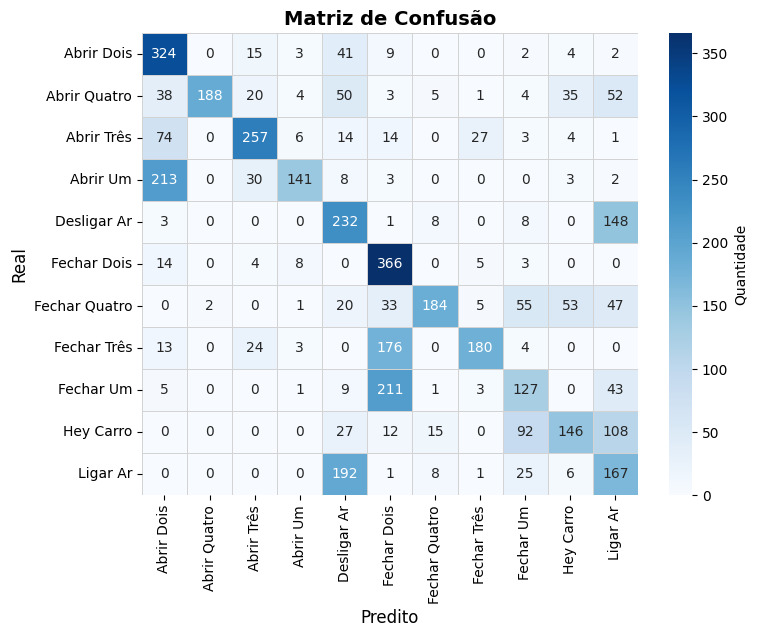

In [26]:
cm = confusion_matrix(targets, predictions)
print(tabulate(cm))

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    linecolor="lightgray",
    cbar_kws={"label": "Quantidade"},
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_,
    annot_kws={"fontsize": 10, "fontfamily": "sans-serif"}
)

plt.xticks(fontsize=10, fontfamily="sans-serif")
plt.yticks(fontsize=10, fontfamily="sans-serif")
plt.xlabel("Predito", fontsize=12, fontfamily="sans-serif")
plt.ylabel("Real", fontsize=12, fontfamily="sans-serif")
plt.title("Matriz de Confusão", fontsize=14, fontfamily="sans-serif", fontweight="bold")

plt.show()


## 12. Relatório de Classificação

In [27]:
print(
    classification_report(
        targets,
        predictions,
        target_names=encoder.classes_
    )
)


               precision    recall  f1-score   support

   Abrir Dois       0.47      0.81      0.60       400
 Abrir Quatro       0.99      0.47      0.64       400
   Abrir Três       0.73      0.64      0.69       400
     Abrir Um       0.84      0.35      0.50       400
  Desligar Ar       0.39      0.58      0.47       400
  Fechar Dois       0.44      0.92      0.60       400
Fechar Quatro       0.83      0.46      0.59       400
  Fechar Três       0.81      0.45      0.58       400
    Fechar Um       0.39      0.32      0.35       400
    Hey Carro       0.58      0.36      0.45       400
     Ligar Ar       0.29      0.42      0.34       400

     accuracy                           0.53      4400
    macro avg       0.62      0.53      0.53      4400
 weighted avg       0.62      0.53      0.53      4400



## 13. Curva de Treinamento (Loss de treino vs. validação)

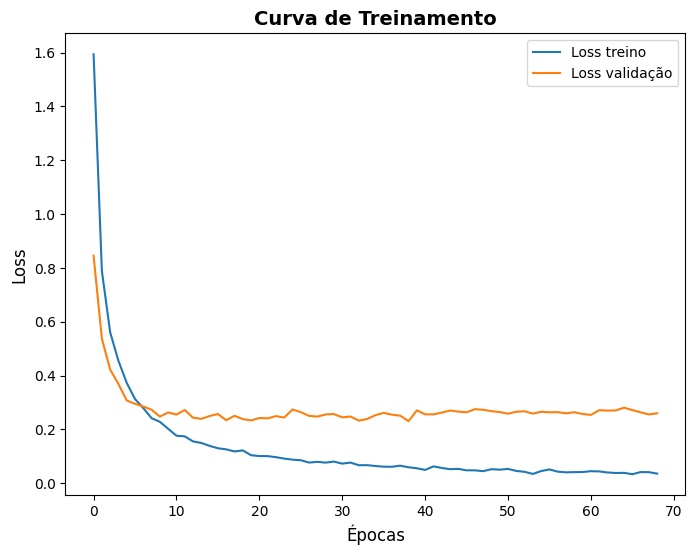

In [28]:
plt.figure(figsize=(8, 6))

plt.plot(train_loss_history, label="Loss treino")
plt.plot(val_loss_history, label="Loss validação")

plt.xlabel("Épocas", fontsize=12, fontfamily="sans-serif")
plt.ylabel("Loss", fontsize=12, fontfamily="sans-serif")
plt.title("Curva de Treinamento", fontsize=14, fontfamily="sans-serif", fontweight="bold")
plt.xticks(fontsize=10, fontfamily="sans-serif")
plt.yticks(fontsize=10, fontfamily="sans-serif")
plt.legend()

plt.show()
